# Exploratory Data Analysis

---
# Introduction

*Centers for Medicare & Medicaid Services (CMS)* is a U.S. federal government agency responsible for administering major public healthcare programs, including Medicare.

**Medicare** is a U.S. federal health insurance program primarily serving people aged 65 and older. Eligibility can also extend to certain people under 65 with qualifying disabilities, End-Stage Renal Disease (ESRD), or Amyotrophic Lateral Sclerosis (ALS).

Medicare is divided into four parts. This project focuses on **Medicare Part B fee-for-service (FFS) data**.

**Medicare Part B** covers a wide range of medically necessary services provided by physicians and other healthcare professionals, including physician services, outpatient services, preventive services, and diagnostic services. Beneficiaries generally pay a monthly Part B premium and an annual deductible. After the deductible, beneficiaries generally pay 20% of the Medicare-approved amount for covered services when the applicable Medicare payment rules are met.

This project uses the **CMS Medicare Physician & Other Practitioners by Provider and Service** dataset to analyze provider-, service-, specialty-, and regional-level patterns in Medicare healthcare services and payments.


## Key Questions

This project focuses on three main questions at the **specialty, regional, and provider peer-group levels**.

### Question 1 — Specialty Level

**How does the gap between provider-submitted charges and Medicare-allowed amounts vary across different specialties?**

Providers from different specialties may have substantially different submitted charges relative to the amounts allowed by Medicare. This question examines the disparity between provider-submitted charges and Medicare-allowed amounts across specialties.

### Question 2 — Regional Level

**What factors contribute to differences in Medicare expenditures across geographic regions?**

How do Medicare payments and service volumes vary across geographic regions, and to what extent are regional differences associated with payment per service, service volume, or both?

### Question 3 — Provider Peer-Group Level

**Which providers have substantially higher submitted charges than their peers for comparable services performed in the same setting?**

Providers performing the same services in similar settings can still have different billing patterns. This question compares providers within appropriate peer groups to identify unusually high or low submitted-charge patterns and narrow down potential outliers for further investigation.


## Objective

The objective of this project is to analyze CMS Medicare Physician & Other Practitioners data to identify and understand patterns in healthcare charges, Medicare payments, service volumes, and provider billing behavior.

The analysis focuses on three levels: **specialty, geographic region, and provider peer groups**. By examining these levels, the project aims to identify meaningful differences in submitted charges, Medicare expenditures, and provider-level billing patterns, while highlighting potential outliers for further investigation.

The results will be supported by a reproducible data pipeline that transforms and validates the raw CMS data before producing the analytical outputs.


---
# Dependencies

In [1]:
import pandas as pd
from pathlib import Path
import os
import matplotlib.pyplot as plt
import seaborn as sns

---
# Data Loading

The raw CMS dataset is stored in the project's `data/raw/` directory. The following code locates the project root dynamically so that the notebook can be run from different working directories on both Windows and Linux.

Only the variables required for this project's analysis are loaded from the raw dataset. The complete filtered dataset is retained as `df_full` for source-level profiling, while a reproducible random sample of 200,000 rows is created as `df` for exploratory analysis and visualization.

A fixed random seed is used so that the same sample can be reproduced across runs.


In [2]:
SAMPLE_SIZE = 200_000

PROJECT_ROOT = Path(os.getcwd())
while not (PROJECT_ROOT / 'data').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

FILE_PATH = PROJECT_ROOT / 'data' / 'raw' / 'Medicare_Physician_Other_Practitioners_by_Provider_and_Service_2022.csv'

df_full = pd.read_csv(
    FILE_PATH,
    usecols=[
        'Rndrng_NPI', 'Rndrng_Prvdr_Type', 'Rndrng_Prvdr_State_Abrvtn',
        'Rndrng_Prvdr_Ent_Cd', 'HCPCS_Cd', 'Place_Of_Srvc',
        'Tot_Benes', 'Tot_Srvcs', 'Tot_Bene_Day_Srvcs',
        'Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt', 'Avg_Mdcr_Pymt_Amt', 'Avg_Mdcr_Stdzd_Amt'
    ],
    low_memory=False
)

df = df_full.sample(n=SAMPLE_SIZE, random_state=42)

print(f"Full dataset rows: {len(df_full):,}")
print(f"Sample rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")

Full dataset rows: 9,755,427
Sample rows: 200,000
Columns: 13


---
# Dataset Inspection

---
## Initial Dataset Inspection

The full filtered dataset is inspected to establish its basic structure before beginning the exploratory analysis. This includes the number of records, available columns, data types, memory usage, and missing values.

The dataset contains **9,755,427 records across 13 selected columns** and requires approximately **968 MB of memory** in its current pandas representation. No missing values were found in any of the selected columns.

These checks establish the initial data-quality baseline for the project. The observed data types and completeness will also be useful when designing the future ingestion and validation steps of the data pipeline, where schema consistency and unexpected missing values should be explicitly checked.


In [3]:
df.head(3)

,Rndrng_NPI,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_State_Abrvtn,Rndrng_Prvdr_Type,HCPCS_Cd,Place_Of_Srvc,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
3351656,1346268067,I,CA,Infectious Disease,99291,F,19,20.0,20,970.000000,233.674500,188.455500,173.877500
4171590,1427314038,I,NV,Diagnostic Radiology,72125,F,13,13.0,13,568.000000,47.860769,29.512308,28.015385
4604675,1477188373,I,TX,Nurse Practitioner,90662,O,17,17.0,17,67.764706,66.465882,66.465882,66.409412


In [4]:
df_full.info()

<class 'pandas.DataFrame'>
RangeIndex: 9755427 entries, 0 to 9755426
Data columns (total 13 columns):
 #   Column                     Dtype  
---  ------                     -----  
 0   Rndrng_NPI                 int64  
 1   Rndrng_Prvdr_Ent_Cd        str    
 2   Rndrng_Prvdr_State_Abrvtn  str    
 3   Rndrng_Prvdr_Type          str    
 4   HCPCS_Cd                   str    
 5   Place_Of_Srvc              str    
 6   Tot_Benes                  int64  
 7   Tot_Srvcs                  float64
 8   Tot_Bene_Day_Srvcs         int64  
 9   Avg_Sbmtd_Chrg             float64
 10  Avg_Mdcr_Alowd_Amt         float64
 11  Avg_Mdcr_Pymt_Amt          float64
 12  Avg_Mdcr_Stdzd_Amt         float64
dtypes: float64(5), int64(3), str(5)
memory usage: 967.6 MB


In [5]:
df_full.isna().sum()

Rndrng_NPI                   0
Rndrng_Prvdr_Ent_Cd          0
Rndrng_Prvdr_State_Abrvtn    0
Rndrng_Prvdr_Type            0
HCPCS_Cd                     0
Place_Of_Srvc                0
Tot_Benes                    0
Tot_Srvcs                    0
Tot_Bene_Day_Srvcs           0
Avg_Sbmtd_Chrg               0
Avg_Mdcr_Alowd_Amt           0
Avg_Mdcr_Pymt_Amt            0
Avg_Mdcr_Stdzd_Amt           0
dtype: int64

---
## Key Profiling Insights & Pipeline Impacts

* **Right Skew to Be Assessed (MAD Candidate):** The distributions exhibit significant upper-tail dispersion and extreme values. This highlights the need for robust statistical methods in provider peer-group analysis (Q3), where the median and Median Absolute Deviation (MAD) will be assessed as alternatives to the mean and standard deviation.

* **Database Typing:** Financial metrics might need to be defined as NUMERIC(12, 2) to avoid issues with floating-point rounding. The total services (Tot_Srvcs) should also be defined as NUMERIC(12, 2) because of fractional split billing (minimum value of 2.50). Additionally, the total beneficiaries (Tot_Benes) and total beneficiary days of services (Tot_Bene_Day_Srvcs) can be be defined as INTEGER.

* **Privacy Floor Verified:** The minimum observed values for Tot_Benes and Tot_Bene_Day_Srvcs are both 11. This is consistent with the dataset's published minimum-count/suppression rules and should be preserved as an observed source characteristic.

* **Zero Division Risk:** The average Medicare allowed amount (Avg_Mdcr_Alowd_Amt) can hit 0.00. To avoid errors in downstream markup calculations (Avg_Sbmtd_Chrg / Avg_Mdcr_Alowd_Amt), it is necessary to implement a NULLIF guard in SQL to prevent pipeline crashes.

In [29]:
numeric_cols = [
    'Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt', 
    'Avg_Mdcr_Pymt_Amt', 'Avg_Mdcr_Stdzd_Amt',
    'Tot_Benes', 'Tot_Srvcs', 'Tot_Bene_Day_Srvcs'
]
print(df_full[numeric_cols].describe().round(2))

       Avg_Sbmtd_Chrg  Avg_Mdcr_Alowd_Amt  Avg_Mdcr_Pymt_Amt  \
count      9755427.00          9755427.00         9755427.00   
mean           398.99              104.98              81.95   
std           1358.12              312.13             249.16   
min              0.00                0.00               0.00   
25%             69.00               27.32              21.31   
50%            166.67               68.54              52.28   
75%            343.00              120.67              89.22   
max          99999.99            59035.73           47043.99   

       Avg_Mdcr_Stdzd_Amt   Tot_Benes   Tot_Srvcs  Tot_Bene_Day_Srvcs  
count          9755427.00  9755427.00  9755427.00          9755427.00  
mean                80.93       84.27      258.22              134.31  
std                248.43     1301.98     6269.63             2116.34  
min                  0.00       11.00        2.50               11.00  
25%                 19.52       17.00       20.00              

---
### Boundary and Zero-Value Validation Key Points

* **Data Integrity Confirmed (No Negative Values):** All 9.75 million records contain non-negative values for all financial and volume measures. We can confidently apply non-negative check constraints (CHECK (col >= 0)) in the database DDL and dbt schema tests.

* **Proof of Zero-Division Safeguards:** The Avg_Mdcr_Alowd_Amt field includes exactly 15 rows with a value of zero. When calculating the provider markup ratio (`Avg_Sbmtd_Chrg / Avg_Mdcr_Alowd_Amt`), it is essential to use an explicit `NULLIF(Avg_Mdcr_Alowd_Amt, 0)` safeguard in SQL to prevent pipeline crashes. But those 15 rows only require exclusion/NULLIF when Avg_Mdcr_Alowd_Amt is a row-level denominator (Question 3), while aggregate specialty totals (Q1) and regional payment totals (Q2) retain all source rows.   

`Note`: Avg_Mdcr_Pymt_Amt contains 109 zero-valued records. These observations require awareness when interpreting payment-based metrics and should be investigated against the CMS field definition before being treated as anomalies.

In [7]:
for col in numeric_cols:
    neg_count = (df_full[col] < 0).sum()
    zero_count = (df_full[col] == 0).sum()
    print(f"{col:20s}: {neg_count} negatives | {zero_count} zeroes")

Avg_Sbmtd_Chrg      : 0 negatives | 0 zeroes
Avg_Mdcr_Alowd_Amt  : 0 negatives | 15 zeroes
Avg_Mdcr_Pymt_Amt   : 0 negatives | 109 zeroes
Avg_Mdcr_Stdzd_Amt  : 0 negatives | 25 zeroes
Tot_Benes           : 0 negatives | 0 zeroes
Tot_Srvcs           : 0 negatives | 0 zeroes
Tot_Bene_Day_Srvcs  : 0 negatives | 0 zeroes


In [23]:
print("\nInspecting the 15 records with Avg_Mdcr_Alowd_Amt == 0:")
zero_allowed = df_full[df_full['Avg_Mdcr_Alowd_Amt'] == 0]
print(zero_allowed[['Rndrng_Prvdr_Type', 'Rndrng_Prvdr_Ent_Cd', 'Rndrng_Prvdr_State_Abrvtn', 'HCPCS_Cd', 'Tot_Srvcs', 'Avg_Sbmtd_Chrg', 'Avg_Mdcr_Pymt_Amt']])


Inspecting the 15 records with Avg_Mdcr_Alowd_Amt == 0:
              Rndrng_Prvdr_Type Rndrng_Prvdr_Ent_Cd Rndrng_Prvdr_State_Abrvtn  \
1389215         Family Practice                   I                        KS   
1814510  Gynecological Oncology                   I                        WA   
1814511  Gynecological Oncology                   I                        WA   
2090795     Physician Assistant                   I                        NE   
2554815              Nephrology                   I                        FL   
2665726       Internal Medicine                   I                        CO   
3360482       Internal Medicine                   I                        MT   
4360395         Family Practice                   I                        VA   
4817988      Nurse Practitioner                   I                        NJ   
5124857      Nurse Practitioner                   I                        MA   
5285119         Family Practice                   I 

---
## Categorical Domain Profiling Takeaways

* **Storage Optimization (Place of Service & Provider Entity Code):** Both attributes have only 2 unique single-character values: 'O' and 'F' for the place of service, and 'I' and 'O' for the entity type. Storing these attributes as CHAR(1) in PostgreSQL optimizes disk storage and improves query performance.
  
* **dbt Schema Test Specification:** The empirical domains directly inform our dbt data contract tests:
  - `Place_Of_Srvc`: `accepted_values: ['O', 'F']`
  - `Rndrng_Prvdr_Ent_Cd`: `accepted_values: ['I', 'O']`
  
* There are 103 unique medical specialties.

In [9]:
cat_cols = ['Rndrng_Prvdr_Type', 'Place_Of_Srvc', 'Rndrng_Prvdr_Ent_Cd']
for col in cat_cols:
    print(f"{col}: {df_full[col].nunique()} unique values")
    print(df_full[col].value_counts().head(5))
    print()

Rndrng_Prvdr_Type: 103 unique values
Rndrng_Prvdr_Type
Diagnostic Radiology    1137764
Internal Medicine        868292
Nurse Practitioner       851917
Family Practice          813473
Physician Assistant      518182
Name: count, dtype: int64

Place_Of_Srvc: 2 unique values
Place_Of_Srvc
O    6233245
F    3522182
Name: count, dtype: int64

Rndrng_Prvdr_Ent_Cd: 2 unique values
Rndrng_Prvdr_Ent_Cd
I    9210142
O     545285
Name: count, dtype: int64



---
## Grain Validation

* **Confirmed Natural Composite Primary Key:** When grouping by `['Rndrng_NPI', 'HCPCS_Cd', 'Place_Of_Srvc']`, there are precisely 9,755,427 unique combinations. This corresponds to all 9,755,427 rows, with no duplicates detected.
* **Database Constraint Specification:** In the PostgreSQL warehouse schema and the downstream dbt models, (rndrng_npi, hcpcs_cd, place_of_srvc) can be designated as the composite primary key. This designation poses no risk of key violation or row fan-out.

In [10]:
grain_cols = ['Rndrng_NPI', 'HCPCS_Cd', 'Place_Of_Srvc']

grain_check = df_full.groupby(grain_cols).size().reset_index(name='row_count')
duplicates = grain_check[grain_check['row_count'] > 1]

print(f"Total rows in dataset:          {len(df_full):,}")
print(f"Unique grain combinations:       {len(grain_check):,}")
print(f"Combinations appearing > 1 time: {len(duplicates):,}")

if len(duplicates) == 0:
    print("\n✓ Grain confirmed — NPI + HCPCS + Place of Service uniquely identifies every row.")
    print("  One row = one provider + one procedure + one setting for the reporting year.")
else:
    print("\n✗ Duplicates found — investigate before schema design.")
    print(duplicates.head(10))

Total rows in dataset:          9,755,427
Unique grain combinations:       9,755,427
Combinations appearing > 1 time: 0

✓ Grain confirmed — NPI + HCPCS + Place of Service uniquely identifies every row.
  One row = one provider + one procedure + one setting for the reporting year.


---
## NPI Validation
### Key Takeaways for National Provider Identifier (NPI) Validation

* **Consistent Federal Format:** All 9,755,427 provider records consist of exactly 10 digits, with no malformed or truncated identifiers.
* **Schema Definition (VARCHAR(10)):** The NPI is a nominal identifier rather than a quantitative measurement. In PostgreSQL DDL and dbt models, it can be stored as `VARCHAR(10)` instead of an integer type. This approach prevents arithmetic evaluation and avoids the accidental removal of leading zeros in future pipeline runs.
* **Reliable Joining:** Keeping the NPI as a uniform 10-character string ensures stable and uncorrupted primary-to-foreign key joins between staging tables, provider dimension tables, and analytical marts.

In [11]:
npi_str = df_full['Rndrng_NPI'].astype(str)
npi_lengths = npi_str.str.len().value_counts().sort_index()

print("NPI length distribution (all should be 10):")
print(npi_lengths)
print()

non_10 = (npi_str.str.len() != 10).sum()
print(f"NPIs not exactly 10 digits: {non_10:,}")

if non_10 == 0:
    print("✓ All NPIs are exactly 10 digits.")
else:
    print("✗ Some NPIs are not 10 digits — investigate.")
    print(df_full[npi_str.str.len() != 10][['Rndrng_NPI']].head(10))

print()
print("Note: NPI is an identifier, not a measurement.")
print("It will be stored as VARCHAR(10) or TEXT in PostgreSQL, not as a numeric type.")
print("Arithmetic on NPIs is meaningless — only equality comparisons matter.")

NPI length distribution (all should be 10):
Rndrng_NPI
10    9755427
Name: count, dtype: int64

NPIs not exactly 10 digits: 0
✓ All NPIs are exactly 10 digits.

Note: NPI is an identifier, not a measurement.
It will be stored as VARCHAR(10) or TEXT in PostgreSQL, not as a numeric type.
Arithmetic on NPIs is meaningless — only equality comparisons matter.


---
## HCPCS Procedure Code Validation

* **Fixed-Width Format Confirmed (CHAR(5))**: All 9,755,427 records contain exactly 5-character procedure codes, representing 6,326 unique HCPCS codes. These can be stored as fixed-width CHAR(5) in PostgreSQL.
  
* **Alphanumeric Structure Confirmed**: The presence of Level II codes (e.g., G0008) indicates that procedure codes must remain as strings/text during the ingestion and transformation processes to avoid null values.

In [12]:
hcpcs_lengths = df_full['HCPCS_Cd'].astype(str).str.len().value_counts().sort_index()

print("HCPCS code length distribution (all should be 5):")
print(hcpcs_lengths)
print()

total_unique_hcpcs = df_full['HCPCS_Cd'].nunique()
print(f"Total unique HCPCS codes: {total_unique_hcpcs:,}")
print()

# Check how many HCPCS codes contain letters (non-numeric characters)
alpha_count = (~df_full['HCPCS_Cd'].astype(str).str.isnumeric()).sum()
print(f"HCPCS codes containing letters: {alpha_count:,}")

# Check for non-5-character codes
non_5 = (df_full['HCPCS_Cd'].astype(str).str.len() != 5).sum()
print(f"Codes not exactly 5 characters: {non_5:,}")

if non_5 == 0:
    print("✓ All HCPCS codes are exactly 5 characters.")
else:
    print("✗ Some codes are not 5 characters — investigate.")

HCPCS code length distribution (all should be 5):
HCPCS_Cd
5    9755427
Name: count, dtype: int64

Total unique HCPCS codes: 6,326

HCPCS codes containing letters: 1,053,862
Codes not exactly 5 characters: 0
✓ All HCPCS codes are exactly 5 characters.


## Geographic Domain Validation Takeaways

* **Storage Typing (CHAR(2)):** All 62 observed geographic codes are exactly 2 characters long. We can define `rndrng_prvdr_state_abrvtn` as a fixed-width CHAR(2) in PostgreSQL DDL to optimize row width and index sizing.
* **Empirical Domain Breadth (62 Values):** In addition to the 50 U.S. states and Washington, D.C., CMS includes 11 valid non-state codes, totaling approximately 23.8k rows. These codes cover other territories, overseas military addresses, Micronesia, as well as foreign and unknown entries.
* **dbt Testing & Regional Modeling (Question 2):**
  - Schema tests that check accepted values must reference the full set of 62 codes in the CMS domain to avoid false alerts in the pipeline.
  - Analytical models for Question 2 should implement an `is_us_state_or_dc` boolean flag. This will help prevent micro-sample territories (such as FM and AS, each with 3 rows) and non-geographic entities (like ZZ and XX) from skewing regional spending metrics or disrupting map visuals.

In [13]:
state_domain = df_full['Rndrng_Prvdr_State_Abrvtn'].value_counts()

print(f"Total unique state/geographic codes: {df_full['Rndrng_Prvdr_State_Abrvtn'].nunique()}")
print()
print("All observed geographic codes (sorted by frequency):")
print(state_domain.to_string())
print()

non_standard = state_domain[~state_domain.index.isin([
    'AL','AK','AZ','AR','CA','CO','CT','DE','FL','GA',
    'HI','ID','IL','IN','IA','KS','KY','LA','ME','MD',
    'MA','MI','MN','MS','MO','MT','NE','NV','NH','NJ',
    'NM','NY','NC','ND','OH','OK','OR','PA','RI','SC',
    'SD','TN','TX','UT','VT','VA','WA','WV','WI','WY','DC'
])]

print(f"\nNon-standard geographic codes (territories, foreign, unknown):")
print(non_standard)

Total unique state/geographic codes: 62

All observed geographic codes (sorted by frequency):
Rndrng_Prvdr_State_Abrvtn
CA    797629
FL    706472
TX    675859
NY    622553
PA    442435
IL    396254
NC    349625
OH    349571
NJ    311541
MI    296155
GA    283049
MA    279480
VA    272806
TN    256487
MD    225085
AZ    212729
IN    205311
MN    201665
WA    199529
MO    191810
SC    181004
WI    173087
AL    162528
CO    151323
KY    140900
LA    136856
CT    121236
OK    117829
AR    106525
IA    105949
OR    104619
KS    104144
MS    103606
NE     77293
NV     74256
UT     71717
WV     54198
NH     53303
NM     46002
ID     45890
ME     40135
DE     38629
MT     35004
SD     34973
RI     34805
ND     28553
DC     26425
HI     26025
AK     21094
WY     19103
PR     18771
VT     18582
GU      1851
VI      1492
ZZ       407
AP       302
XX       298
AE       274
AA       242
MP       146
FM         3
AS         3


Non-standard geographic codes (territories, foreign, unknown):
Rndrng_Pr

---
## Distribution Shape & Skewness Analysis Takeaways

* **Severe Right Skewness Confirmed:** All financial metrics exhibit extreme positive skewness, with values ranging from 27.34 for submitted charges to over 42.9 for Medicare payments. The mean submitted charge is nearly twice the median or more.
* **Significant Disparity in the Top 1% Tail:** While 99% of provider charges are at or below `$4,000.00`, maximum values reach as high as $99,999.99, which significantly skews standard parametric measures.
* **Methodological Justification for Q3:** Standard Gaussian outlier detection methods, such as Z-scores and standard deviation, may be distorted due to the variance inflation caused by outliers. Therefore, the Median Absolute Deviation (MAD) is necessary for modeling anomalies within peer groups in dbt.

In [14]:
print("Distribution shape analysis — full dataset:")
print(f"{'Column':<25} {'Mean':>10} {'Median':>10} {'Skewness':>10} {'P99':>12}")
print("-" * 70)

for col in ['Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt', 
            'Avg_Mdcr_Pymt_Amt', 'Avg_Mdcr_Stdzd_Amt']:
    mean = df_full[col].mean()
    median = df_full[col].median()
    skew = df_full[col].skew()
    p99 = df_full[col].quantile(0.99)
    print(f"{col:<25} {mean:>10.2f} {median:>10.2f} {skew:>10.2f} {p99:>12.2f}")

print()
print("Interpretation: skewness > 1 indicates right skew.")
print("Skewness > 2 or > 3 means extreme right skew where mean >> median.")
print("This directly informs whether robust statistics (MAD) are appropriate for Q3.")

Distribution shape analysis — full dataset:
Column                          Mean     Median   Skewness          P99
----------------------------------------------------------------------
Avg_Sbmtd_Chrg                398.99     166.67      27.34      4000.00
Avg_Mdcr_Alowd_Amt            104.98      68.54      42.96       816.61
Avg_Mdcr_Pymt_Amt              81.95      52.28      42.95       650.40
Avg_Mdcr_Stdzd_Amt             80.93      52.91      43.49       636.60

Interpretation: skewness > 1 indicates right skew.
Skewness > 2 or > 3 means extreme right skew where mean >> median.
This directly informs whether robust statistics (MAD) are appropriate for Q3.


---
## Key Takeaways from Financial Distribution Visual Profiling

* **Evidence of Mean Distortion:** In all four financial columns, the parametric mean (indicated by the red line) is significantly shifted to the right of the median (represented by the navy line). This is particularly evident in submitted charges, where the mean is 404, compared to a median of 167. This discrepancy visually highlights the effect of extreme outliers.
* **Concentration of Billing Amounts:** In both Medicare allowed amounts and standardized amounts, the charges are highly concentrated between 20 and 100.
* **Validation of Methodological Approach:** The significant concentration in the lower quartile, along with the long right tails, indicates that parametric models relying on standard deviation can be adversely affected by outlier influence. Therefore, the use of non-parametric and robust measures, such as the median and median absolute deviation (MAD), may be considered for modeling in Question 3 peer groups.

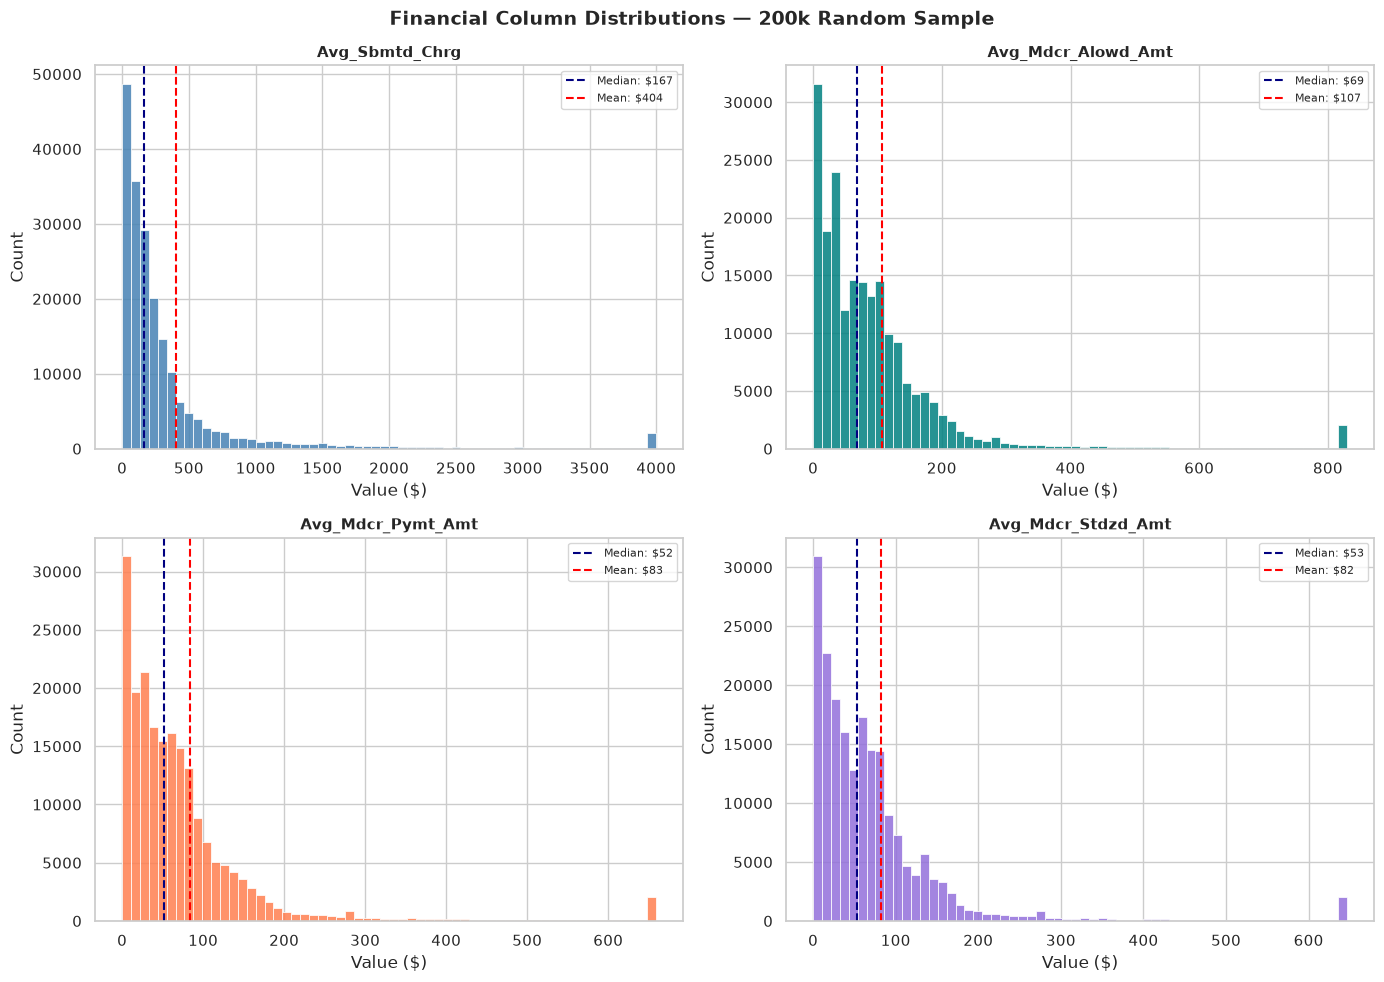

Note: clipped at 99th percentile for visual clarity — extreme upper tail exists but is not shown.


In [15]:
sns.set_theme(style='whitegrid')

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Financial Column Distributions — 200k Random Sample', fontsize=14, fontweight='bold')

cols = ['Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt', 'Avg_Mdcr_Pymt_Amt', 'Avg_Mdcr_Stdzd_Amt']
palette = ['steelblue', 'teal', 'coral', 'mediumpurple']

for ax, col, color in zip(axes.flat, cols, palette):
    clipped = df[col].clip(upper=df[col].quantile(0.99))
    sns.histplot(clipped, bins=60, color=color, ax=ax, edgecolor='white', alpha=0.85)
    
    ax.axvline(df[col].median(), color='navy', linestyle='--', linewidth=1.5,
               label=f'Median: ${df[col].median():,.0f}')
    ax.axvline(df[col].mean(), color='red', linestyle='--', linewidth=1.5,
               label=f'Mean: ${df[col].mean():,.0f}')
    
    ax.set_title(col, fontsize=11, fontweight='bold')
    ax.set_xlabel('Value ($)')
    ax.set_ylabel('Count')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(PROJECT_ROOT / 'notebooks' / 'charts' / 'financial_distributions.png', dpi=150)
plt.show()

print("Note: clipped at 99th percentile for visual clarity — extreme upper tail exists but is not shown.")

---
# Business Questions Analysis

---
## Question 1 — Specialty-Level Markup Disparity Analysis

### Service-Weighted Metric Definition and Interpretations

* **Service-Weighted Aggregation Logic:** Since the financial data is reported as per-service averages, using a simple unweighted average of the row-level ratios could allow low-volume providers to distort specialty benchmarks. Therefore, total dollar volumes are reconstructed first by calculating (Total Services * Average Amount) and then summed by specialty before calculating the ratio of total submitted amounts to total allowed amounts.

* **Extreme Markup in Anesthesia and Acute Care:** Anesthesia specialties show the highest levels of billing disparity. This includes categories such as Anesthesiology Assistants, Certified Registered Nurse Anesthetists (CRNAs), and Anesthesiology itself, followed by Radiation Therapy Centers and Emergency Medicine. A high ratio indicates that estimated submitted-charge dollars are large relative to estimated allowed dollars within a specialty. This analysis does not establish why the disparity exists or prove inappropriate billing.

* **Sample Size and Entity Stratification for the Gold Mart:** Several high-markup categories are associated with institutional facilities (identified by Rndrng_Prvdr_Ent_Cd = 'O') or have very small sample sizes with limited records. In the downstream dbt Gold Mart (mart_specialty_markup_disparity), it would be good to retain record counts and total services alongside the markup ratio. 

* **Sample Size and Entity Context:** Retain row counts, distinct-provider counts, and total services alongside the specialty ratio. These measures help readers distinguish high ratios supported by substantial data from ratios based on smaller groups. Low-volume specialties remain visible in the exploratory ranking, but their results should be interpreted with greater caution.

In [50]:
df_full['est_submitted_dollars'] = df_full['Tot_Srvcs'] * df_full['Avg_Sbmtd_Chrg']
df_full['est_allowed_dollars']   = df_full['Tot_Srvcs'] * df_full['Avg_Mdcr_Alowd_Amt']
df_full['is_org']                = (df_full['Rndrng_Prvdr_Ent_Cd'] == 'O').astype(int)

specialty_markup = (
    df_full.groupby('Rndrng_Prvdr_Type')
    .agg(
        total_submitted = ('est_submitted_dollars', 'sum'),
        total_allowed   = ('est_allowed_dollars',   'sum'),
        total_services  = ('Tot_Srvcs',             'sum'),
        provider_count  = ('Rndrng_NPI',            'nunique'),
        row_count       = ('Rndrng_NPI',            'count'),
        org_pct         = ('is_org',                'mean')
    )
    .assign(
        markup_ratio=lambda x: x["total_submitted"].div(
            x["total_allowed"].where(x["total_allowed"] > 0)
        )
    )
    .sort_values('markup_ratio', ascending=False)  
)

print("Top 20 specialties by service-weighted markup ratio:")
print(specialty_markup[['markup_ratio', 'total_services', 'provider_count', 'row_count', 'org_pct']].head(20).round(2))



Top 20 specialties by service-weighted markup ratio:
                                                markup_ratio  total_services  \
Rndrng_Prvdr_Type                                                              
Anesthesiology Assistant                               10.59        112432.0   
Certified Registered Nurse Anesthetist (CRNA)           8.61       4180372.3   
Anesthesiology                                          7.86      12492280.4   
Radiation Therapy Center                                6.31        137576.0   
Emergency Medicine                                      6.05      26434967.6   
Ambulatory Surgical Center                              4.93      25570900.3   
Independent Diagnostic Testing Facility (IDTF)          4.83      24910445.0   
Diagnostic Radiology                                    4.83     190144513.8   
Neurosurgery                                            4.79       2078355.5   
Mammography Center                                      4.20       

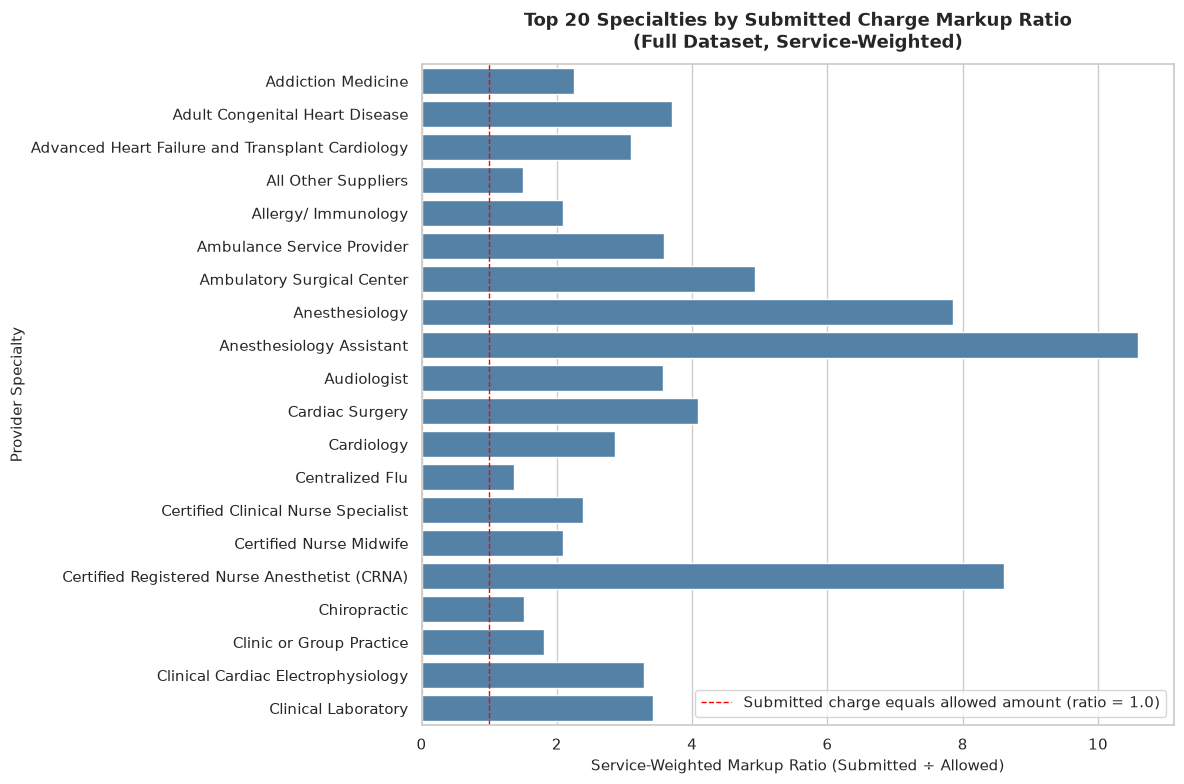

In [44]:
top20 = specialty_markup.head(20).reset_index()
sns.set_theme(style='whitegrid')
plt.figure(figsize=(12, 8))

ax = sns.barplot(
    data=top20,
    x='markup_ratio',
    y='Rndrng_Prvdr_Type',
    color='steelblue',
)

ax.axvline(
    1.0,
    color='red',
    linestyle='--',
    linewidth=1,
    label= 'Submitted charge equals allowed amount (ratio = 1.0)',
)

ax.set_title(
    'Top 20 Specialties by Submitted Charge Markup Ratio\n(Full Dataset,'
    ' Service-Weighted)',
    fontsize=13,
    fontweight='bold',
    pad=12,
)
ax.set_xlabel('Service-Weighted Markup Ratio (Submitted ÷ Allowed)', fontsize=11)
ax.set_ylabel('Provider Specialty', fontsize=11)
ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig(
    PROJECT_ROOT / 'notebooks' / 'charts' / 'q1_specialty_markup.png', dpi=150
)
plt.show()

---
## Question 2 — Regional-Level Expenditure Analysis

### Metrics and Interpretation

This analysis organizes records by the state abbreviation of the rendering provider and compares the following metrics: estimated total Medicare payments, estimated total standardized payments, total service volume, and payment per service.

- **Total Payment and Service Volume:** These metrics indicate the overall scale of reported activities within each provider-location group. Estimated total payments are derived from service counts and average payment amounts.
- **Payment per Service:** This metric assesses the intensity of payments for each reported service. Variations in this measure can reflect differences in the types of services provided as well as variations in payment rates; however, it does not serve as a pure measure of regional cost.
- **Actual versus Standardized Payment:** This comparison highlights the difference between actual payments and standardized payments as determined by CMS. It should not be interpreted solely as a reflection of cost-of-living differences or as isolating the impact of a single geographic adjustment.
- **Geographic Scope:** The state code reflects the reported location of the rendering provider, rather than the residence of the beneficiary. Total services represent service counts, not the counts of unique beneficiaries.

This analysis is descriptive in nature. It illustrates how expenditure patterns vary regionally in relation to service volume and payment per service, but it does not confirm that any specific factor caused these differences.

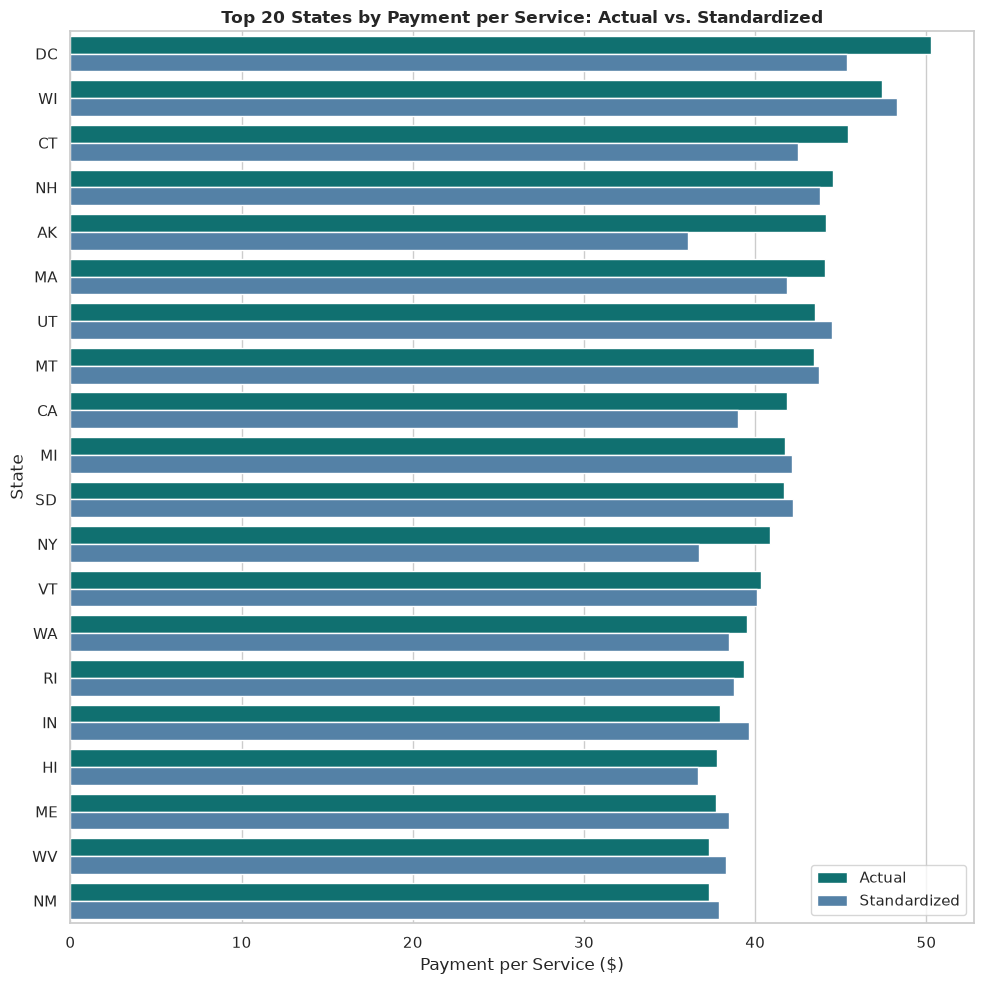

Top 15 states/DC by estimated total Medicare payment:


,total_services,total_payment,total_stdzd_payment,payment_per_service,stdzd_per_service,actual_minus_standardized_per_service
Rndrng_Prvdr_State_Abrvtn,,,,,,
CA,255133175.3,1.067557e+10,9.948103e+09,41.84,38.99,2.85
FL,273150384.8,8.324954e+09,8.278906e+09,30.48,30.31,0.17
TX,187695189.2,6.472469e+09,6.511941e+09,34.48,34.69,-0.21
NY,152730061.9,6.238195e+09,5.610969e+09,40.84,36.74,4.11
IL,122949646.7,3.827139e+09,3.736171e+09,31.13,30.39,0.74
NJ,111169019.7,3.677051e+09,3.446237e+09,33.08,31.00,2.08
PA,101342883.3,3.568067e+09,3.549720e+09,35.21,35.03,0.18
NC,85452039.5,2.707968e+09,2.766527e+09,31.69,32.38,-0.69
MD,72923907.2,2.665930e+09,2.541489e+09,36.56,34.85,1.71


In [47]:
df_full['est_payment_dollars'] = df_full['Tot_Srvcs'] * df_full['Avg_Mdcr_Pymt_Amt']
df_full['est_stdzd_dollars']   = df_full['Tot_Srvcs'] * df_full['Avg_Mdcr_Stdzd_Amt']

regional = (
    df_full.groupby('Rndrng_Prvdr_State_Abrvtn')
    .agg(
        total_services       = ('Tot_Srvcs',            'sum'),
        total_payment        = ('est_payment_dollars',  'sum'),
        total_stdzd_payment  = ('est_stdzd_dollars',    'sum'),
    )
    .assign(
        payment_per_service = lambda x: x['total_payment'] / x['total_services'],
        stdzd_per_service   = lambda x: x['total_stdzd_payment'] / x['total_services'],
    )
    .sort_values('payment_per_service', ascending=False)
)

us_states = [
    'AL','AK','AZ','AR','CA','CO','CT','DE','FL','GA',
    'HI','ID','IL','IN','IA','KS','KY','LA','ME','MD',
    'MA','MI','MN','MS','MO','MT','NE','NV','NH','NJ',
    'NM','NY','NC','ND','OH','OK','OR','PA','RI','SC',
    'SD','TN','TX','UT','VT','VA','WA','WV','WI','WY','DC'
]
regional_us = regional[regional.index.isin(us_states)]

top20 = (
    regional_us.sort_values('payment_per_service', ascending=False)
    .head(20)
    .reset_index()
)
top20_long = top20.melt(
    id_vars='Rndrng_Prvdr_State_Abrvtn',
    value_vars=['payment_per_service', 'stdzd_per_service'],
    var_name='Type',
    value_name='Amount',
)
top20_long['Type'] = top20_long['Type'].map(
    {'payment_per_service': 'Actual', 'stdzd_per_service': 'Standardized'}
)

plt.figure(figsize=(10, 10))
sns.barplot(
    data=top20_long,
    y='Rndrng_Prvdr_State_Abrvtn',
    x='Amount',
    hue='Type',
    palette=['teal', 'steelblue'],
)
plt.title(
    'Top 20 States by Payment per Service: Actual vs. Standardized',
    fontweight='bold',
)
plt.xlabel('Payment per Service ($)')
plt.ylabel('State')
plt.legend(title=None)
plt.tight_layout()
plt.show()

regional_display = regional_us.copy()

regional_display["actual_minus_standardized_per_service"] = (
    regional_display["payment_per_service"]
    - regional_display["stdzd_per_service"]
)

regional_table_columns = [
    "total_services",
    "total_payment",
    "total_stdzd_payment",
    "payment_per_service",
    "stdzd_per_service",
    "actual_minus_standardized_per_service",
]

print("Top 15 states/DC by estimated total Medicare payment:")

display(
    regional_display
    .sort_values("total_payment", ascending=False)[regional_table_columns]
    .head(15)
    .round(2)
)

---
## Question 3 — Provider Peer-Group Outlier Analysis

In [27]:
df_q3 = df_full[
    (df_full['Rndrng_Prvdr_Ent_Cd'] == 'I') & 
    (df_full['Avg_Mdcr_Alowd_Amt'] > 0)
].copy()

peer_group_sizes = (
    df_q3.groupby(['Rndrng_Prvdr_Type', 'HCPCS_Cd', 'Place_Of_Srvc'])
    ['Rndrng_NPI'].nunique()
    .reset_index(name='provider_count')
)

print(f"Total peer groups (all sizes): {len(peer_group_sizes):,}")
print()
print("Peer group size distribution:")
size_bins = [1, 5, 10, 30, 100, 500, float('inf')]
size_labels = ['1-4', '5-9', '10-29', '30-99', '100-499', '500+']
peer_group_sizes['size_category'] = pd.cut(
    peer_group_sizes['provider_count'],
    bins=size_bins, labels=size_labels, right=False
)
print(peer_group_sizes['size_category'].value_counts().sort_index())
print()

qualifying = peer_group_sizes[peer_group_sizes['provider_count'] >= 30]
print(f"Peer groups with ≥ 30 providers (qualifying for outlier analysis): {len(qualifying):,}")
print(f"Peer groups excluded (< 30 providers): {len(peer_group_sizes) - len(qualifying):,}")
print(f"Retention rate: {len(qualifying)/len(peer_group_sizes)*100:.1f}%")

Total peer groups (all sizes): 56,355

Peer group size distribution:
size_category
1-4        31239
5-9         6647
10-29       7160
30-99       4915
100-499     3765
500+        2629
Name: count, dtype: int64

Peer groups with ≥ 30 providers (qualifying for outlier analysis): 11,309
Peer groups excluded (< 30 providers): 45,046
Retention rate: 20.1%


### Key Takeaways on Peer-Group Cohort Sizing and Minimum Sample Thresholds

* **Defining Peer Groups and Entity Scope:** Peer cohorts are categorized based on a combination of (Rndrng_Prvdr_Type, HCPCS_Cd, Place_Of_Srvc) and are limited to individual practitioners (Rndrng_Prvdr_Ent_Cd = 'I') with positive allowed amounts (Avg_Mdcr_Alowd_Amt > 0). This approach ensures fair clinical comparisons by avoiding distortions from organizational facilities.

* **Sparsity in Rare Procedure Combinations:** Out of 56,355 distinct peer groups, 31,239 (55.4%) consist of only 1 to 4 providers, and 45,046 (79.9%) have fewer than 30 providers.

* **Proposed Minimum Group Size (provider_count >= 30):** A total of 11,309 peer groups (20.1% retention rate) meet this proposed minimum size threshold. This serves as a practical screening rule for downstream database modeling (HAVING COUNT(DISTINCT rndrng_npi) >= 30) rather than a guarantee of statistical validity. This threshold should remain provisional until outlier behavior is assessed across all qualifying groups.

Peer group: Internal Medicine | HCPCS 99214 | O
Cohort size:  44,818 providers
Median:       1.811
Mean:         2.043
MAD:          0.478
Std Dev:      0.937
Skewness:     2.899

Median + 2×MAD threshold: 2.766
Median + 3×MAD threshold: 3.244

Providers exceeding Median + 2×MAD: 6,777 (15.1%)
Providers exceeding Median + 3×MAD: 3,781 (8.4%)


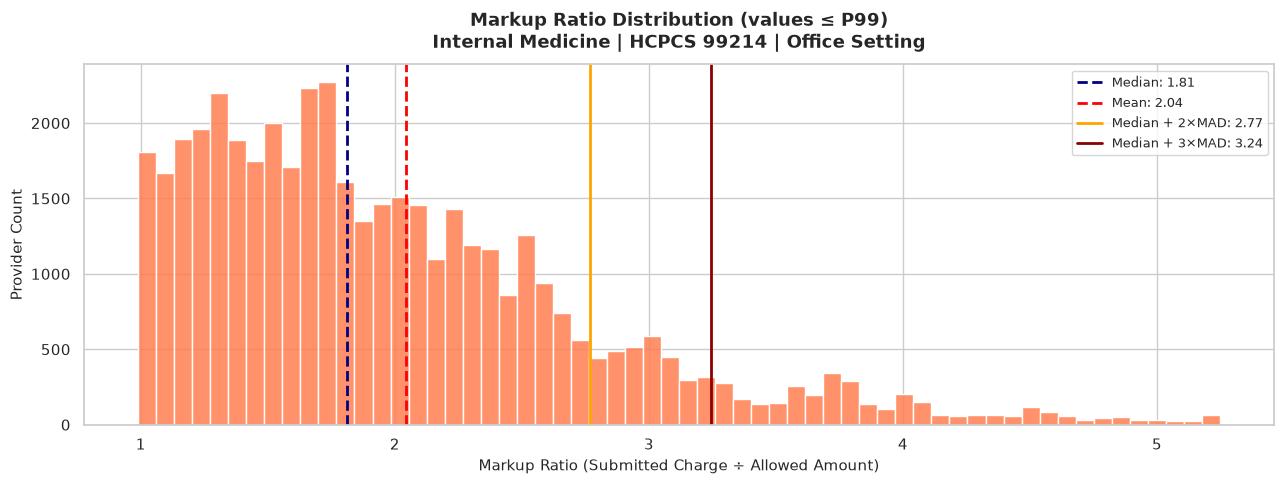

Histogram omits 449 records above P99; original ratios are retained for all calculations.


In [48]:
sample_specialty = 'Internal Medicine'
sample_pos = 'O'

top_hcpcs = (
    df_q3[
        (df_q3['Rndrng_Prvdr_Type'] == sample_specialty) &
        (df_q3['Place_Of_Srvc'] == sample_pos)
    ]['HCPCS_Cd'].value_counts().index[0]
)

peer_group = df_q3[
    (df_q3['Rndrng_Prvdr_Type'] == sample_specialty) &
    (df_q3['HCPCS_Cd'] == top_hcpcs) &
    (df_q3['Place_Of_Srvc'] == sample_pos)
].copy()

peer_group['markup_ratio'] = peer_group['Avg_Sbmtd_Chrg'] / peer_group['Avg_Mdcr_Alowd_Amt']

median_val = peer_group['markup_ratio'].median()
mean_val   = peer_group['markup_ratio'].mean()
mad_val    = (peer_group['markup_ratio'] - median_val).abs().median()
skew_val   = peer_group['markup_ratio'].skew()

print(f"Peer group: {sample_specialty} | HCPCS {top_hcpcs} | {sample_pos}")
print(f"Cohort size:  {len(peer_group):,} providers")
print(f"Median:       {median_val:.3f}")
print(f"Mean:         {mean_val:.3f}")
print(f"MAD:          {mad_val:.3f}")
print(f"Std Dev:      {peer_group['markup_ratio'].std():.3f}")
print(f"Skewness:     {skew_val:.3f}")
print()
print("Median + 2×MAD threshold:", round(median_val + 2 * mad_val, 3))
print("Median + 3×MAD threshold:", round(median_val + 3 * mad_val, 3))
print()
flagged_2mad = (peer_group['markup_ratio'] > median_val + 2 * mad_val).sum()
flagged_3mad = (peer_group['markup_ratio'] > median_val + 3 * mad_val).sum()
print(f"Providers exceeding Median + 2×MAD: {flagged_2mad:,} ({flagged_2mad/len(peer_group)*100:.1f}%)")
print(f"Providers exceeding Median + 3×MAD: {flagged_3mad:,} ({flagged_3mad/len(peer_group)*100:.1f}%)")

sns.set_theme(style='whitegrid')

p99 = peer_group["markup_ratio"].quantile(0.99)

plot_ratios = peer_group.loc[
    peer_group["markup_ratio"] <= p99,
    "markup_ratio"
]

above_p99_count = (
    peer_group["markup_ratio"] > p99
).sum()

fig, ax = plt.subplots(figsize=(13, 5))

sns.histplot(
    data=plot_ratios,
    bins=60,
    color='coral',
    edgecolor='white',
    alpha=0.85,
    ax=ax,
    kde=False,  
)

ax.axvline(
    median_val,
    color='navy',
    linestyle='--',
    linewidth=2,
    label=f'Median: {median_val:.2f}',
)
ax.axvline(
    mean_val,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Mean: {mean_val:.2f}',
)
ax.axvline(
    median_val + 2 * mad_val,
    color='orange',
    linestyle='-',
    linewidth=2,
    label=f'Median + 2×MAD: {median_val + 2*mad_val:.2f}',
)
ax.axvline(
    median_val + 3 * mad_val,
    color='darkred',
    linestyle='-',
    linewidth=2,
    label=f'Median + 3×MAD: {median_val + 3*mad_val:.2f}',
)

ax.set_title(
    f'Markup Ratio Distribution (values ≤ P99)\n'
    f'{sample_specialty} | HCPCS {top_hcpcs} | Office Setting',
    fontsize=13,
    fontweight='bold',
    pad=12,
)
ax.set_xlabel(
    'Markup Ratio (Submitted Charge ÷ Allowed Amount)', fontsize=11
)
ax.set_ylabel('Provider Count', fontsize=11)
ax.legend(fontsize=9, loc='upper right')

plt.tight_layout()
plt.savefig(
    PROJECT_ROOT / 'notebooks' / 'charts' / 'q3_peer_distribution.png', dpi=150
)
plt.show()
print(
    f"Histogram omits {above_p99_count:,} records above P99; "
    "original ratios are retained for all calculations."
)

### Key Takeaways from the Single-Cohort MAD Prototype

- **Prototype cohort:** The Internal Medicine / HCPCS 99214 / office-setting cohort contains 44,818 individual-practitioner records in the current run.

- **Distribution shape:** The observed markup-ratio distribution is right-skewed (skewness 2.899), with a mean of 2.043 above a median of 1.811. These statistics describe this cohort and should not be generalized automatically to every peer group.

- **Candidate raw-MAD thresholds:** The threshold median + 2 × raw MAD is 2.766 and flags 15.1% of the cohort. The threshold median + 3 × raw MAD is 3.244 and flags 8.4%. These percentages describe the behavior of the candidate rules in this cohort; they do not establish that either cutoff is a valid anomaly detector.

- **Zero-MAD handling:** Under the current raw-MAD threshold formula, a zero MAD makes the threshold equal to the median. Any normalized MAD score that divides by MAD will require an explicit zero-MAD handling rule.

- **Visualization limit:** The histogram displays ratios at or below the 99th percentile. Values above that percentile are omitted from the histogram for visibility only; they remain in the dataset and in all summary statistics and threshold calculations.

- **Next step:** Keep both thresholds provisional. Evaluate their behavior across eligible peer groups and inspect flagged records before deciding which rule, if any, should be adopted in the downstream dbt mart.

In [49]:
q3_ratios = (
    df_q3["Avg_Sbmtd_Chrg"]
    / df_q3["Avg_Mdcr_Alowd_Amt"]
)

below_one = q3_ratios < 1

print(f"Eligible Q3 records: {len(df_q3):,}")
print(
    f"Ratios below 1: {below_one.sum():,} "
    f"({below_one.mean():.2%})"
)

below_one_examples = df_q3.loc[
    below_one,
    [
        "Rndrng_NPI",
        "Rndrng_Prvdr_Type",
        "HCPCS_Cd",
        "Place_Of_Srvc",
        "Tot_Srvcs",
        "Avg_Sbmtd_Chrg",
        "Avg_Mdcr_Alowd_Amt",
    ],
].copy()

below_one_examples["markup_ratio"] = q3_ratios.loc[below_one]

display(below_one_examples.head(10))


max_charge = df_full["Avg_Sbmtd_Chrg"].max()

at_max_charge = df_full.loc[
    df_full["Avg_Sbmtd_Chrg"].eq(max_charge),
    [
        "Rndrng_NPI",
        "Rndrng_Prvdr_Type",
        "HCPCS_Cd",
        "Place_Of_Srvc",
        "Avg_Sbmtd_Chrg",
        "Avg_Mdcr_Alowd_Amt",
        "Avg_Mdcr_Pymt_Amt",
    ],
]

print(f"Maximum observed submitted charge: ${max_charge:,.2f}")
print(f"Records at the observed maximum: {len(at_max_charge):,}")

display(at_max_charge.head(20))

at_99999_99 = df_full.loc[
    df_full["Avg_Sbmtd_Chrg"].round(2).eq(99_999.99)
]

print(
    "Records with submitted charge rounding to $99,999.99: "
    f"{len(at_99999_99):,}"
)

Eligible Q3 records: 9,210,127
Ratios below 1: 9,333 (0.10%)


,Rndrng_NPI,Rndrng_Prvdr_Type,HCPCS_Cd,Place_Of_Srvc,Tot_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,markup_ratio
549,1003003856,Family Practice,G0402,O,14.0,200.000000,200.945000,0.995297
3967,1003023581,Nephrology,99497,O,18.0,85.480000,85.540556,0.999292
5806,1003037169,Otolaryngology,99214,O,34.0,67.000000,67.005588,0.999917
8000,1003047689,Physical Therapist in Private Practice,97164,O,40.0,61.000000,61.292250,0.995232
10650,1003067661,Pathology,84165,F,71.0,12.500000,12.578873,0.993730
10651,1003067661,Pathology,84166,F,12.0,12.500000,12.590000,0.992851
13618,1003081985,Interventional Cardiology,36473,O,61.0,1454.300000,1459.764098,0.996257
18928,1003122003,Hospitalist,99217,F,21.0,67.710000,67.858571,0.997811
18929,1003122003,Hospitalist,99219,F,12.0,125.409167,125.859167,0.996425
18930,1003122003,Hospitalist,99220,F,30.0,170.200667,170.394000,0.998865


Maximum observed submitted charge: $99,999.99
Records at the observed maximum: 22


,Rndrng_NPI,Rndrng_Prvdr_Type,HCPCS_Cd,Place_Of_Srvc,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt
128707,1013212927,Ambulatory Surgical Center,63685,F,99999.99,21478.369412,17133.629412
796030,1083176309,Ambulatory Surgical Center,63685,F,99999.99,23126.062667,18465.230667
1591159,1164484572,Ambulatory Surgical Center,69930,F,99999.99,43543.780417,34741.876667
2337301,1235750431,Ambulatory Surgical Center,27447,F,99999.99,8466.046279,6749.391395
2423451,1245654615,Ambulatory Surgical Center,27279,F,99999.99,13058.940357,10416.190357
2423455,1245654615,Ambulatory Surgical Center,63685,F,99999.99,23509.760909,18745.440909
2432364,1245759356,Ambulatory Surgical Center,33264,F,99999.99,26555.629333,21184.232000
2558410,1265435614,Ambulatory Surgical Center,63685,F,99999.99,22770.451818,18169.511818
2849407,1295119584,Ambulatory Surgical Center,33263,F,99999.99,18650.940769,14865.816923
2859063,1295204113,Ambulatory Surgical Center,27447,F,99999.99,10227.805294,8159.412353


Records with submitted charge rounding to $99,999.99: 22


---

# Key Findings

## 1. Dataset Structure and Quality

The 2022 CMS Medicare Physician & Other Practitioners by Provider and Service extract contains **9,755,427 records** and 13 selected analytical columns. No missing values were detected in these selected columns. Validation found that the combination of rendering provider NPI, HCPCS procedure code, and place of service is unique across the extract, supporting the proposed analytical grain of one provider–procedure–place-of-service record for the reporting period.

All observed NPIs have 10 digits, all observed HCPCS codes have five characters, and the extract contains 6,326 distinct HCPCS codes, 103 provider-type categories, and 62 provider-state/geographic codes. No negative values were observed in the selected financial and volume fields.

The extract contains 15 records with a zero average Medicare allowed amount, 109 records with a zero average Medicare payment amount, and 25 records with a zero average standardized payment amount. These values were identified during profiling and retained in the full dataset; eligibility depends on the metric being calculated.

`Tot_Srvcs` contains fractional values, and average financial fields have more than two decimal places. These characteristics need to be preserved when the database schema is designed.

## 2. Specialty-Level Submitted-Charge Disparity

The analysis calculates a service-weighted aggregate ratio by multiplying the number of services by the average submitted charge and average allowed amount, summing those estimated dollar amounts by provider type, and dividing total estimated submitted dollars by total estimated allowed dollars.

The highest ratios in the current result include:

- Anesthesiology Assistant: **10.59**
- Certified Registered Nurse Anesthetist (CRNA): **8.61**
- Anesthesiology: **7.86**
- Radiation Therapy Center: **6.31**
- Emergency Medicine: **6.05**

These values show that estimated submitted-charge dollars are substantially greater than estimated allowed dollars for these categories. The ratio is descriptive: it does not by itself establish why the difference exists or prove inappropriate billing.

Row counts, distinct-provider counts, total services, and provider entity type provide essential context. Lower-volume categories should be interpreted more cautiously rather than being automatically removed from exploratory ranking.

## 3. Regional Expenditure and Payment Intensity

The regional analysis separates aggregate service volume and estimated payment totals from payment per service. This distinction matters because high total expenditure can be associated with large service volume, higher payment per service, or both.

Comparing actual and standardized payment per service also reveals differences in the payment amounts before and after geographic standardization. These differences are descriptive and should not be treated as proof that one geographic factor caused a regional expenditure pattern.

The companion regional table provides the additional context needed to compare total expenditure, service volume, and payment intensity side by side.

## 4. Provider Peer-Group Analysis

Provider anomaly analysis is restricted to individual practitioners with a positive average Medicare allowed amount, because the row-level submitted-to-allowed ratio is undefined when its denominator is zero.

The current peer-group design combines provider type, HCPCS code, and place of service. Of the **56,355** observed peer groups, **11,309 (20.1%)** meet the proposed minimum size of 30 distinct providers. This is a candidate eligibility threshold, not a guarantee of statistical reliability.

In the Internal Medicine / HCPCS 99214 / office-setting prototype, the cohort contains **44,818 providers**. The median markup ratio is **1.811**, the mean is **2.043**, the raw MAD is **0.478**, and the observed skewness is **2.899**.

The candidate threshold `median + 2 × raw MAD` is **2.766** and flags **15.1%** of this cohort. The candidate threshold `median + 3 × raw MAD` is **3.244** and flags **8.4%**. These results describe how the candidate rules behave in this cohort; they do not establish that either threshold is a validated anomaly detector.

The ratio audit identified **9,333 records (0.10% of eligible Q3 records)** with ratios below 1. This observation does not justify an unconditional rule that all submitted-to-allowed ratios must be at least 1. The audit also identified 22 records at the observed maximum submitted charge of $99,999.99; this maximum should not become an enforced source limit without supporting documentation.

---

# Conclusion and Pipeline Implications

## Conclusion

This exploratory analysis establishes a reproducible starting point for examining submitted charges, allowed amounts, Medicare payments, regional utilization, and provider peer-group variation in the 2022 CMS dataset.

The three business questions require different measures and eligibility rules. The specialty-level analysis uses service-weighted aggregate submitted and allowed amounts. The regional analysis compares estimated payment totals, service volume, and payment per service. The provider anomaly prototype calculates row-level ratios only where the allowed amount is positive and compares providers within similar provider-type, procedure-code, and place-of-service groups.

The findings are descriptive rather than causal. A large submitted-to-allowed ratio is not, by itself, evidence of fraud, inappropriate billing, profit, or excess Medicare payment. Likewise, differences between regional actual and standardized payments do not independently establish why regional expenditure patterns differ.

The current MAD thresholds remain exploratory candidates. Further evaluation across eligible peer groups and inspection of flagged providers are required before adopting a production anomaly rule.

## Implications for the Data Pipeline

1. **Preserve source data and precision.** Retain the original source values in the raw layer. Choose staging numeric types and scale after evaluating the actual source precision, fractional service counts, and expected value ranges. Treat NPIs and HCPCS codes as identifiers rather than numeric measures.

2. **Apply metric-specific rules.** Do not globally remove records because `Avg_Mdcr_Alowd_Amt` equals zero. Q1 and Q2 use the full dataset under the current analytical definitions; Q3 requires a positive allowed amount for its row-level ratio. Document counts and reasons for metric-specific exclusions.

3. **Build validation rules from evidence.** Test record grain, identifier formats, nulls, accepted codes, numeric precision, and source-supported boundaries. Do not enforce `markup_ratio >= 1` or a submitted-charge maximum merely because an exploratory result suggests a pattern. Investigate unexpected values rather than silently discarding them.

4. **Keep outlier detection provisional.** Apply a minimum peer-group size only as a clearly documented eligibility choice. Account for zero MAD if a normalized score is introduced, evaluate candidate thresholds across multiple cohorts, and retain evidence about flagged records before choosing a production rule.

5. **Keep transformations reproducible.** Implement validated data contracts and analytical definitions in version-controlled PostgreSQL/dbt models. Maintain a clear distinction between raw data preservation, staging-level type normalization, intermediate calculations, and reporting marts.

The next implementation phase should translate these findings into a schema and transformation design without hard-coding assumptions that the EDA has not yet validated.